In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Set visualization style
sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Dataset URL
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"

# Column names
columns = [
    'Variance',
    'Skewness',
    'Curtosis',
    'Entropy',
    'Class'
]

# Load dataset
df = pd.read_csv(url, header=None, names=columns)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head(10)

,Variance,Skewness,Curtosis,Entropy,Class
0,3.62160,8.6661,-2.80730,-0.44699,0
1,4.54590,8.1674,-2.45860,-1.46210,0
2,3.86600,-2.6383,1.92420,0.10645,0
3,3.45660,9.5228,-4.01120,-3.59440,0
4,0.32924,-4.4552,4.57180,-0.98880,0
5,4.36840,9.6718,-3.96060,-3.16250,0
6,3.59120,3.0129,0.72888,0.56421,0
7,2.09220,-6.8100,8.46360,-0.60216,0
8,3.20320,5.7588,-0.75345,-0.61251,0
9,1.53560,9.1772,-2.27180,-0.73535,0


In [4]:
print("Number of records:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)

Number of records: 1372
Number of columns: 5
Dataset shape: (1372, 5)


In [5]:
# Display data types of all columns

print("Column Data Types:")
print(df.dtypes)

Column Data Types:
Variance    float64
Skewness    float64
Curtosis    float64
Entropy     float64
Class         int64
dtype: object


In [6]:
# Check missing values in each column

print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
Variance    0
Skewness    0
Curtosis    0
Entropy     0
Class       0
dtype: int64

Total Missing Values:
0


In [7]:
# Check duplicate records

duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 24


In [8]:
# Generate descriptive statistics

df.describe()

,Variance,Skewness,Curtosis,Entropy,Class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


In [9]:
# Count records belonging to each class

class_counts = df['Class'].value_counts().sort_index()

print("Class Distribution:")
print(class_counts)

# Calculate percentages

class_percentages = (
    df['Class'].value_counts(normalize=True).sort_index() * 100
)

print("\nClass Percentages:")
print(class_percentages.round(2))

Class Distribution:
Class
0    762
1    610
Name: count, dtype: int64

Class Percentages:
Class
0    55.54
1    44.46
Name: proportion, dtype: float64


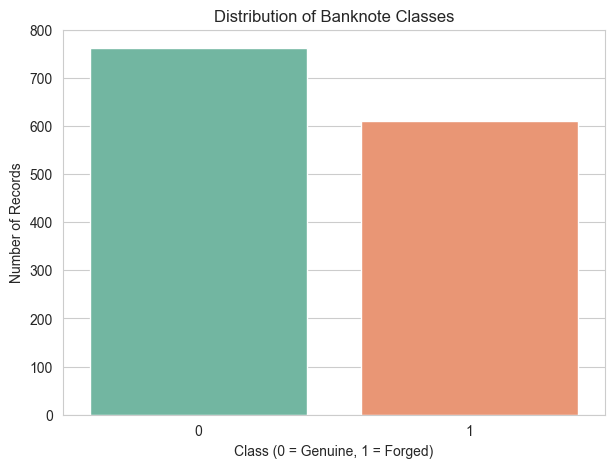

In [10]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Class',
    hue='Class',
    palette='Set2',
    legend=False
)

plt.title("Distribution of Banknote Classes")
plt.xlabel("Class (0 = Genuine, 1 = Forged)")
plt.ylabel("Number of Records")

plt.show()

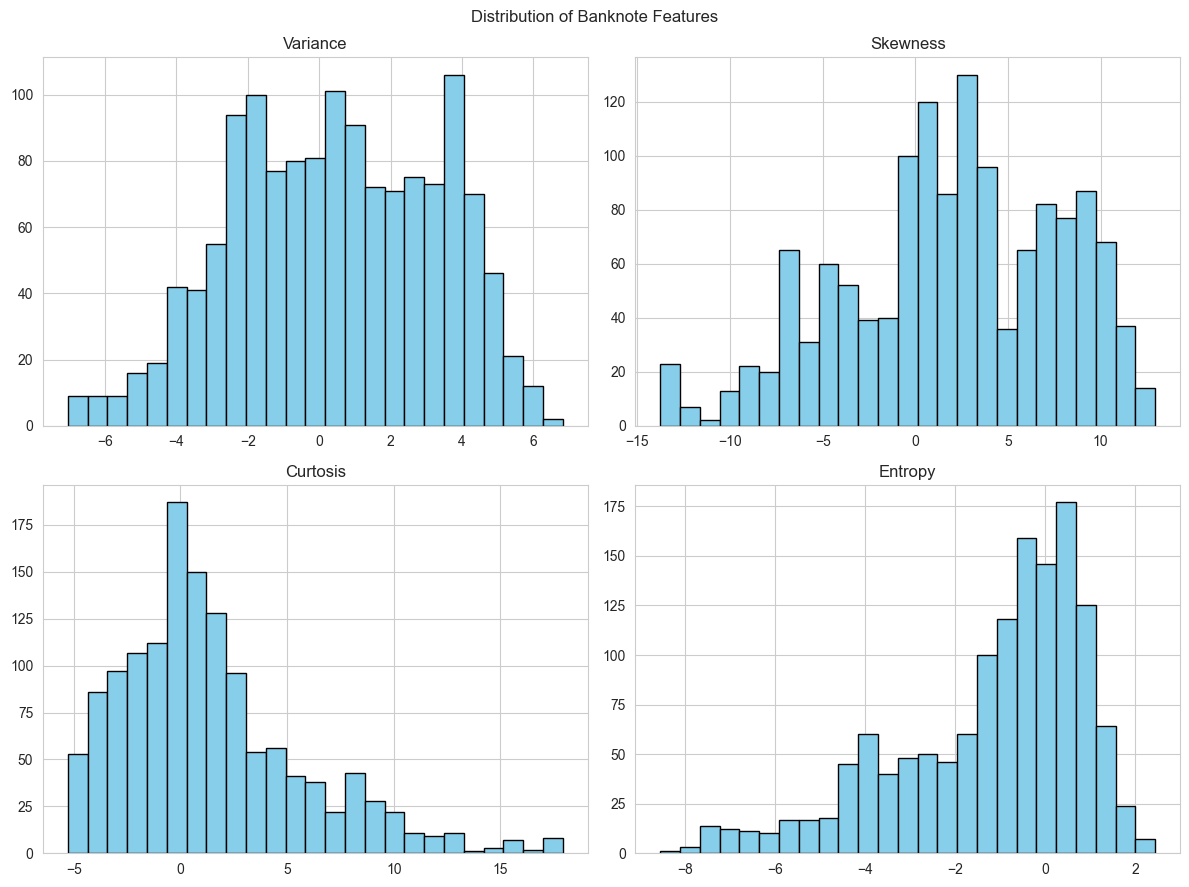

In [11]:
features = [
    'Variance',
    'Skewness',
    'Curtosis',
    'Entropy'
]

df[features].hist(
    figsize=(12, 9),
    bins=25,
    color='skyblue',
    edgecolor='black'
)

plt.suptitle("Distribution of Banknote Features")

plt.tight_layout()
plt.show()

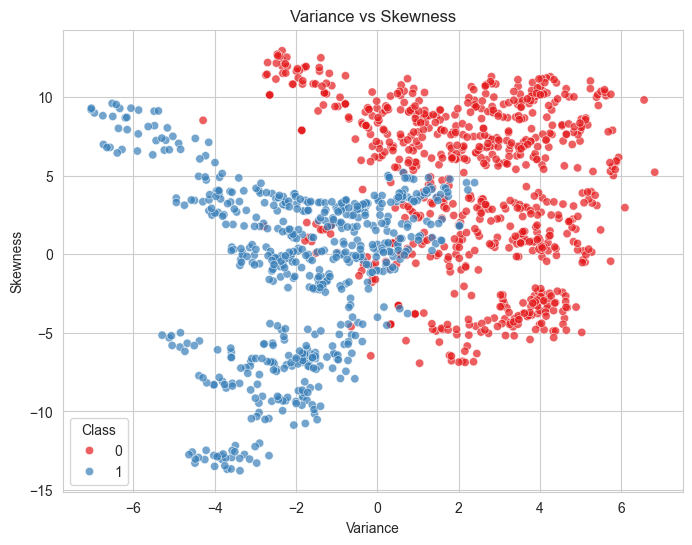

In [12]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='Variance',
    y='Skewness',
    hue='Class',
    palette='Set1',
    alpha=0.7
)

plt.title("Variance vs Skewness")
plt.xlabel("Variance")
plt.ylabel("Skewness")

plt.show()

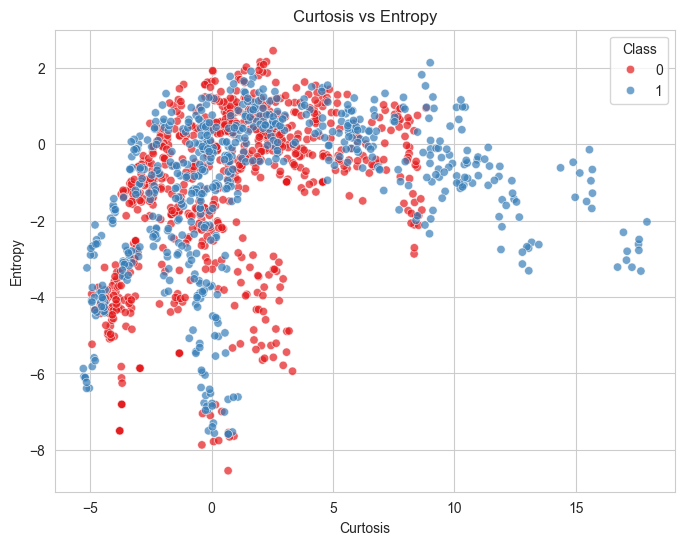

In [13]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='Curtosis',
    y='Entropy',
    hue='Class',
    palette='Set1',
    alpha=0.7
)

plt.title("Curtosis vs Entropy")
plt.xlabel("Curtosis")
plt.ylabel("Entropy")

plt.show()

In [14]:
# Select input features
X = df[['Variance', 'Skewness', 'Curtosis', 'Entropy']]

# Select target variable
y = df['Class']

# Display shapes
print("Input features (X):", X.shape)
print("Target variable (y):", y.shape)

print("\nNumber of input features:", X.shape[1])

print("\nFirst five input records:")
display(X.head())

print("\nFirst five target values:")
display(y.head())

Input features (X): (1372, 4)
Target variable (y): (1372,)

Number of input features: 4

First five input records:


,Variance,Skewness,Curtosis,Entropy
0,3.62160,8.6661,-2.8073,-0.44699
1,4.54590,8.1674,-2.4586,-1.46210
2,3.86600,-2.6383,1.9242,0.10645
3,3.45660,9.5228,-4.0112,-3.59440
4,0.32924,-4.4552,4.5718,-0.98880



First five target values:


0    0
1    0
2    0
3    0
4    0
Name: Class, dtype: int64

In [15]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes

print("Training data size:", X_train.shape)
print("Testing data size:", X_test.shape)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

Training data size: (1097, 4)
Testing data size: (275, 4)

Training records: 1097
Testing records: 275


In [16]:
print("Training Class Distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting Class Distribution:")
print(y_test.value_counts().sort_index())

Training Class Distribution:
Class
0    609
1    488
Name: count, dtype: int64

Testing Class Distribution:
Class
0    153
1    122
Name: count, dtype: int64


In [17]:
# Create StandardScaler object

scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

print("\nScaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Feature scaling completed successfully!

Scaled training data shape: (1097, 4)
Scaled testing data shape: (275, 4)


In [18]:
# Check the mean and standard deviation of scaled training features

print("Mean of scaled training features:")
print(X_train_scaled.mean(axis=0))

print("\nStandard deviation of scaled training features:")
print(X_train_scaled.std(axis=0))

Mean of scaled training features:
[-8.90607349e-18  2.50989344e-17 -1.29542887e-17 -8.09643044e-18]

Standard deviation of scaled training features:
[1. 1. 1. 1.]


In [19]:
# Create Logistic Regression model

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model

model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [20]:
print("Model Parameters:")

print("Maximum iterations:", model.max_iter)

print("Model coefficients:")
print(model.coef_)

print("\nModel intercept:")
print(model.intercept_)

Model Parameters:
Maximum iterations: 1000
Model coefficients:
[[-4.66600886 -4.8065245  -4.39885792  0.25796555]]

Model intercept:
[-1.39990338]


In [21]:
# Predict class labels

y_pred = model.predict(X_test_scaled)

print("Predictions generated successfully!")

print("\nFirst 15 predictions:")
print(y_pred[:15])

Predictions generated successfully!

First 15 predictions:
[0 1 0 1 1 1 0 0 0 1 0 1 0 0 0]


In [22]:
# Create comparison dataframe

comparison = pd.DataFrame({
    'Actual Class': y_test.values,
    'Predicted Class': y_pred
})

print("Actual vs Predicted Classes:")

display(comparison.head(15))

Actual vs Predicted Classes:


,Actual Class,Predicted Class
0,0,0
1,1,1
2,0,0
3,1,1
4,1,1
5,1,1
6,0,0
7,0,0
8,0,0
9,1,1


In [23]:
# Predict probabilities for both classes

y_prob = model.predict_proba(X_test_scaled)

probability_results = pd.DataFrame({
    'Actual Class': y_test.values,
    'Predicted Class': y_pred,
    'Probability Class 0': y_prob[:, 0],
    'Probability Class 1': y_prob[:, 1]
})

display(probability_results.head(10))

,Actual Class,Predicted Class,Probability Class 0,Probability Class 1
0,0,0,0.999576,0.000424
1,1,1,0.033572,0.966428
2,0,0,0.755631,0.244369
3,1,1,0.035568,0.964432
4,1,1,0.006959,0.993041
5,1,1,0.259981,0.740019
6,0,0,0.999274,0.000726
7,0,0,0.999799,0.000201
8,0,0,0.996741,0.003259
9,1,1,0.077905,0.922095


In [24]:
comparison['Correct'] = (
    comparison['Actual Class'] ==
    comparison['Predicted Class']
)

print("Correct Predictions:")
display(comparison[comparison['Correct']].head(10))

print("Incorrect Predictions:")
display(comparison[~comparison['Correct']].head(10))

Correct Predictions:


,Actual Class,Predicted Class,Correct
0,0,0,True
1,1,1,True
2,0,0,True
3,1,1,True
4,1,1,True
5,1,1,True
6,0,0,True
7,0,0,True
8,0,0,True
9,1,1,True


Incorrect Predictions:


,Actual Class,Predicted Class,Correct
70,0,1,False
114,0,1,False
121,0,1,False
125,0,1,False
140,0,1,False
162,0,1,False
221,0,1,False
223,0,1,False


In [25]:
# Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, pos_label=1
)

recall = recall_score(
    y_test, y_pred, pos_label=1
)

f1 = f1_score(
    y_test, y_pred, pos_label=1
)

# Display results

print("LOGISTIC REGRESSION EVALUATION")
print("--------------------------------")

print("Accuracy:", round(accuracy, 4))
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")

print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

LOGISTIC REGRESSION EVALUATION
--------------------------------
Accuracy: 0.9709
Accuracy Percentage: 97.09 %
Precision: 0.9385
Recall: 1.0
F1 Score: 0.9683


In [26]:
print("CLASSIFICATION REPORT")
print("======================")

report = classification_report(
    y_test,
    y_pred,
    target_names=[
        'Genuine (Class 0)',
        'Forged (Class 1)'
    ]
)

print(report)

CLASSIFICATION REPORT
                   precision    recall  f1-score   support

Genuine (Class 0)       1.00      0.95      0.97       153
 Forged (Class 1)       0.94      1.00      0.97       122

         accuracy                           0.97       275
        macro avg       0.97      0.97      0.97       275
     weighted avg       0.97      0.97      0.97       275



In [27]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

print("Confusion Matrix:")
print(cm)

# Extract values
tn, fp, fn, tp = cm.ravel()

print("\nTrue Negative (TN):", tn)
print("False Positive (FP):", fp)
print("False Negative (FN):", fn)
print("True Positive (TP):", tp)

Confusion Matrix:
[[145   8]
 [  0 122]]

True Negative (TN): 145
False Positive (FP): 8
False Negative (FN): 0
True Positive (TP): 122


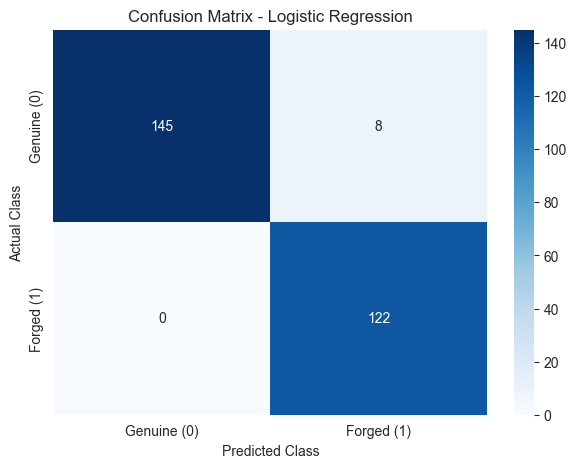

In [28]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Genuine (0)', 'Forged (1)'],
    yticklabels=['Genuine (0)', 'Forged (1)']
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

In [29]:
thresholds = [0.30, 0.50, 0.70]

threshold_results = []

for threshold in thresholds:

    # Generate predictions
    threshold_pred = (
        y_prob[:, 1] >= threshold
    ).astype(int)

    # Calculate metrics
    acc = accuracy_score(y_test, threshold_pred)

    prec = precision_score(
        y_test,
        threshold_pred,
        zero_division=0
    )

    rec = recall_score(
        y_test,
        threshold_pred,
        zero_division=0
    )

    f1_value = f1_score(
        y_test,
        threshold_pred,
        zero_division=0
    )

    # Calculate confusion matrix
    matrix = confusion_matrix(
        y_test,
        threshold_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = matrix.ravel()

    threshold_results.append({
        'Threshold': threshold,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1 Score': f1_value,
        'TN': tn,
        'FP': fp,
        'FN': fn,
        'TP': tp
    })

# Create comparison table
threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Accuracy,Precision,Recall,F1 Score,TN,FP,FN,TP
0,0.3,0.9709,0.9385,1.0,0.9683,145,8,0,122
1,0.5,0.9709,0.9385,1.0,0.9683,145,8,0,122
2,0.7,0.9964,0.9919,1.0,0.9959,152,1,0,122


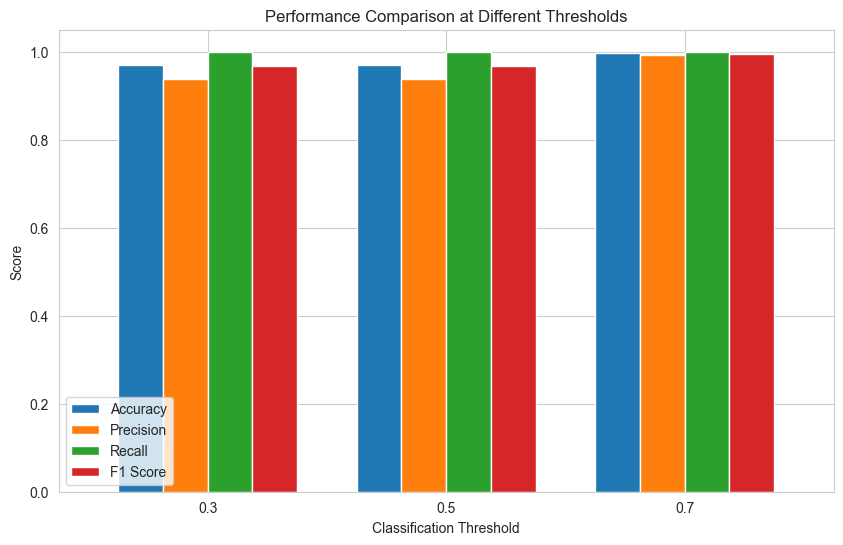

In [30]:
metrics = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1 Score'
]

threshold_df.set_index('Threshold')[metrics].plot(
    kind='bar',
    figsize=(10, 6),
    width=0.75
)

plt.title("Performance Comparison at Different Thresholds")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")

plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc='lower left')

plt.show()

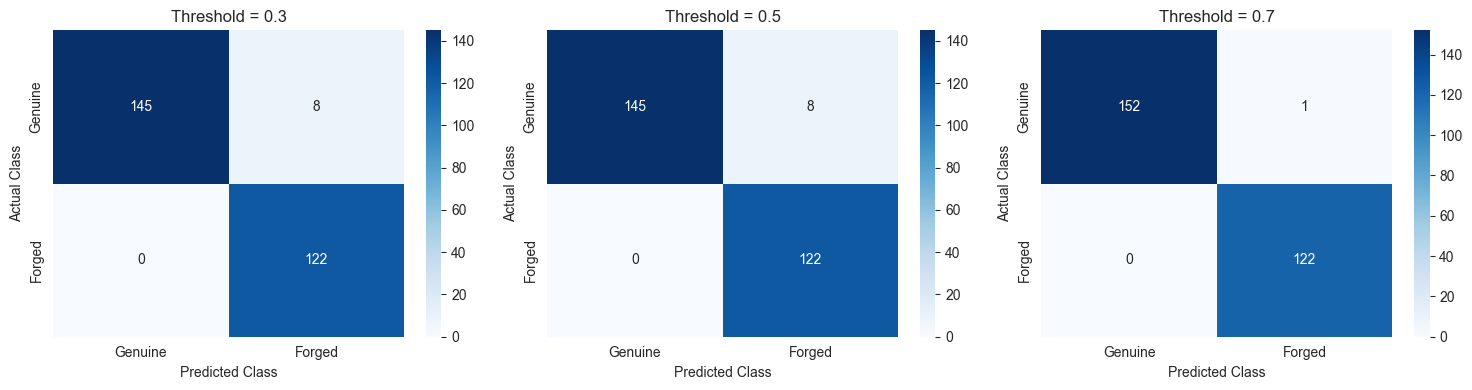

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, threshold in zip(axes, thresholds):

    threshold_pred = (
        y_prob[:, 1] >= threshold
    ).astype(int)

    cm_threshold = confusion_matrix(
        y_test,
        threshold_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm_threshold,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax,
        xticklabels=['Genuine', 'Forged'],
        yticklabels=['Genuine', 'Forged']
    )

    ax.set_title(f'Threshold = {threshold}')
    ax.set_xlabel('Predicted Class')
    ax.set_ylabel('Actual Class')

plt.tight_layout()
plt.show()

In [32]:
# Step 12: Descriptive Statistics

print("DESCRIPTIVE STATISTICS OF BANKNOTE DATASET")

df.describe()

DESCRIPTIVE STATISTICS OF BANKNOTE DATASET


,Variance,Skewness,Curtosis,Entropy,Class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


In [33]:
# Step 13: Class Distribution

# Count records in each class
class_counts = df['Class'].value_counts().sort_index()

# Calculate percentages
class_percentages = (
    df['Class'].value_counts(normalize=True).sort_index() * 100
)

# Display results
print("CLASS DISTRIBUTION")
print("------------------")

print("\nNumber of records:")
print(class_counts)

print("\nPercentage of records:")
print(class_percentages.round(2))

CLASS DISTRIBUTION
------------------

Number of records:
Class
0    762
1    610
Name: count, dtype: int64

Percentage of records:
Class
0    55.54
1    44.46
Name: proportion, dtype: float64


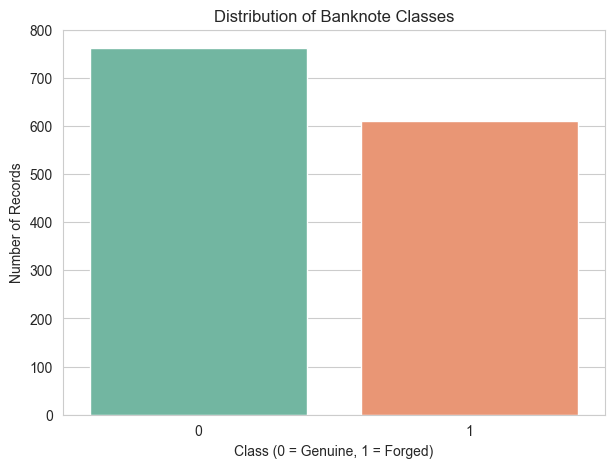

In [34]:
# Step 14: Visualise Class Distribution

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Class',
    hue='Class',
    palette='Set2',
    legend=False
)

plt.title("Distribution of Banknote Classes")
plt.xlabel("Class (0 = Genuine, 1 = Forged)")
plt.ylabel("Number of Records")

plt.show()

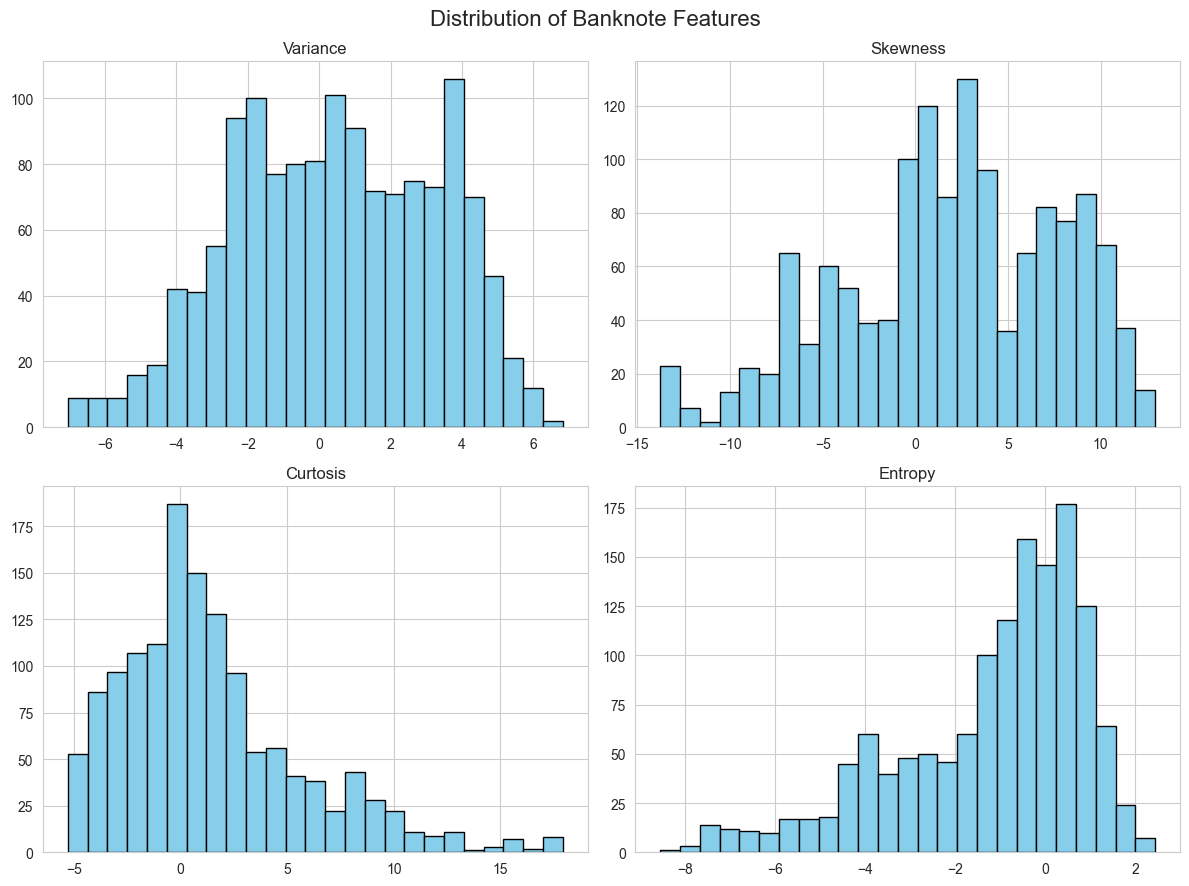

In [35]:
# Step 16: Histograms of all four features

features = [
    'Variance',
    'Skewness',
    'Curtosis',
    'Entropy'
]

df[features].hist(
    figsize=(12, 9),
    bins=25,
    color='skyblue',
    edgecolor='black'
)

plt.suptitle("Distribution of Banknote Features", fontsize=16)

plt.tight_layout()
plt.show()

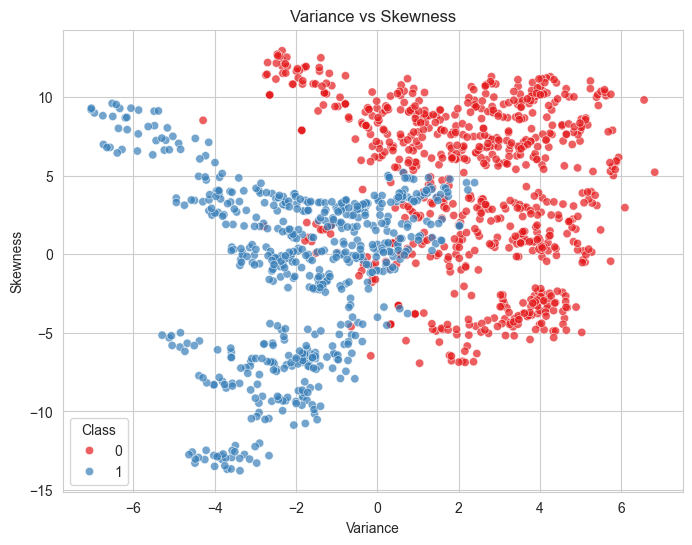

In [36]:
# Step 17: Variance vs Skewness

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='Variance',
    y='Skewness',
    hue='Class',
    palette='Set1',
    alpha=0.7
)

plt.title("Variance vs Skewness")
plt.xlabel("Variance")
plt.ylabel("Skewness")
plt.legend(title="Class")

plt.show()

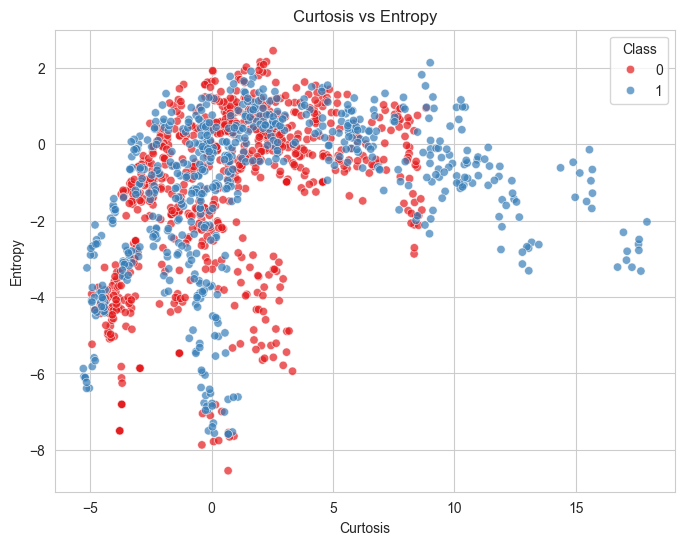

In [37]:
# Step 18: Curtosis vs Entropy

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='Curtosis',
    y='Entropy',
    hue='Class',
    palette='Set1',
    alpha=0.7
)

plt.title("Curtosis vs Entropy")
plt.xlabel("Curtosis")
plt.ylabel("Entropy")
plt.legend(title="Class")

plt.show()

In [38]:
# Step 20: Separate Input Features and Target

# Input features
X = df[['Variance', 'Skewness', 'Curtosis', 'Entropy']]

# Target variable
y = df['Class']

print("Number of input features:", X.shape[1])

print("Shape of X:", X.shape)

print("Shape of y:", y.shape)

print("\nFirst five input records:")
display(X.head())

print("\nFirst five target records:")
display(y.head())

Number of input features: 4
Shape of X: (1372, 4)
Shape of y: (1372,)

First five input records:


,Variance,Skewness,Curtosis,Entropy
0,3.62160,8.6661,-2.8073,-0.44699
1,4.54590,8.1674,-2.4586,-1.46210
2,3.86600,-2.6383,1.9242,0.10645
3,3.45660,9.5228,-4.0112,-3.59440
4,0.32924,-4.4552,4.5718,-0.98880



First five target records:


0    0
1    0
2    0
3    0
4    0
Name: Class, dtype: int64

In [39]:
# Step 21: Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

Training data shape: (1097, 4)
Testing data shape: (275, 4)

Training records: 1097
Testing records: 275


In [40]:
# Check training and testing class distributions

print("Training Class Distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting Class Distribution:")
print(y_test.value_counts().sort_index())

Training Class Distribution:
Class
0    609
1    488
Name: count, dtype: int64

Testing Class Distribution:
Class
0    153
1    122
Name: count, dtype: int64


In [41]:
# Step 23: Feature Scaling

scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

print("\nTraining scaled shape:", X_train_scaled.shape)

print("Testing scaled shape:", X_test_scaled.shape)

Feature scaling completed successfully!

Training scaled shape: (1097, 4)
Testing scaled shape: (275, 4)


In [42]:
# Check mean and standard deviation

print("Mean of scaled training features:")
print(X_train_scaled.mean(axis=0))

print("\nStandard deviation of scaled training features:")
print(X_train_scaled.std(axis=0))

Mean of scaled training features:
[-8.90607349e-18  2.50989344e-17 -1.29542887e-17 -8.09643044e-18]

Standard deviation of scaled training features:
[1. 1. 1. 1.]


In [43]:
# Step 25: Logistic Regression Model

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [44]:
print("Model Parameters")

print("\nMaximum Iterations:")
print(model.max_iter)

print("\nModel Coefficients:")
print(model.coef_)

print("\nModel Intercept:")
print(model.intercept_)

Model Parameters

Maximum Iterations:
1000

Model Coefficients:
[[-4.66600886 -4.8065245  -4.39885792  0.25796555]]

Model Intercept:
[-1.39990338]


In [45]:
# Predict class labels

y_pred = model.predict(X_test_scaled)

print("Predictions generated successfully!")

print("\nFirst 15 predictions:")
print(y_pred[:15])

Predictions generated successfully!

First 15 predictions:
[0 1 0 1 1 1 0 0 0 1 0 1 0 0 0]


In [46]:
comparison = pd.DataFrame({
    'Actual Class': y_test.values,
    'Predicted Class': y_pred
})

display(comparison.head(15))

,Actual Class,Predicted Class
0,0,0
1,1,1
2,0,0
3,1,1
4,1,1
5,1,1
6,0,0
7,0,0
8,0,0
9,1,1


In [47]:
# Predict probabilities for both classes

y_prob = model.predict_proba(X_test_scaled)

probability_results = pd.DataFrame({
    'Actual Class': y_test.values,
    'Predicted Class': y_pred,
    'Probability Class 0': y_prob[:, 0],
    'Probability Class 1': y_prob[:, 1]
})

display(probability_results.head(10))

,Actual Class,Predicted Class,Probability Class 0,Probability Class 1
0,0,0,0.999576,0.000424
1,1,1,0.033572,0.966428
2,0,0,0.755631,0.244369
3,1,1,0.035568,0.964432
4,1,1,0.006959,0.993041
5,1,1,0.259981,0.740019
6,0,0,0.999274,0.000726
7,0,0,0.999799,0.000201
8,0,0,0.996741,0.003259
9,1,1,0.077905,0.922095


In [48]:
comparison['Correct Prediction'] = (
    comparison['Actual Class'] ==
    comparison['Predicted Class']
)

print("Correct Predictions:")
display(comparison[comparison['Correct Prediction']].head(10))

print("\nIncorrect Predictions:")
display(comparison[~comparison['Correct Prediction']].head(10))

Correct Predictions:


,Actual Class,Predicted Class,Correct Prediction
0,0,0,True
1,1,1,True
2,0,0,True
3,1,1,True
4,1,1,True
5,1,1,True
6,0,0,True
7,0,0,True
8,0,0,True
9,1,1,True



Incorrect Predictions:


,Actual Class,Predicted Class,Correct Prediction
70,0,1,False
114,0,1,False
121,0,1,False
125,0,1,False
140,0,1,False
162,0,1,False
221,0,1,False
223,0,1,False


In [49]:
# Step 31: Model Evaluation

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, pos_label=1)

recall = recall_score(y_test, y_pred, pos_label=1)

f1 = f1_score(y_test, y_pred, pos_label=1)

print("MODEL EVALUATION RESULTS")
print("------------------------")

print("Accuracy:", round(accuracy, 4))
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")

print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

MODEL EVALUATION RESULTS
------------------------
Accuracy: 0.9709
Accuracy Percentage: 97.09 %
Precision: 0.9385
Recall: 1.0
F1 Score: 0.9683


In [50]:
# Step 32: Classification Report

print("CLASSIFICATION REPORT")
print("=====================")

print(classification_report(
    y_test,
    y_pred,
    target_names=[
        'Genuine (Class 0)',
        'Forged (Class 1)'
    ]
))

CLASSIFICATION REPORT
                   precision    recall  f1-score   support

Genuine (Class 0)       1.00      0.95      0.97       153
 Forged (Class 1)       0.94      1.00      0.97       122

         accuracy                           0.97       275
        macro avg       0.97      0.97      0.97       275
     weighted avg       0.97      0.97      0.97       275



In [51]:
# Step 33: Confusion Matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

print("Confusion Matrix:")
print(cm)

# Extract TN, FP, FN and TP

tn, fp, fn, tp = cm.ravel()

print("\nTrue Negative (TN):", tn)
print("False Positive (FP):", fp)
print("False Negative (FN):", fn)
print("True Positive (TP):", tp)

Confusion Matrix:
[[145   8]
 [  0 122]]

True Negative (TN): 145
False Positive (FP): 8
False Negative (FN): 0
True Positive (TP): 122


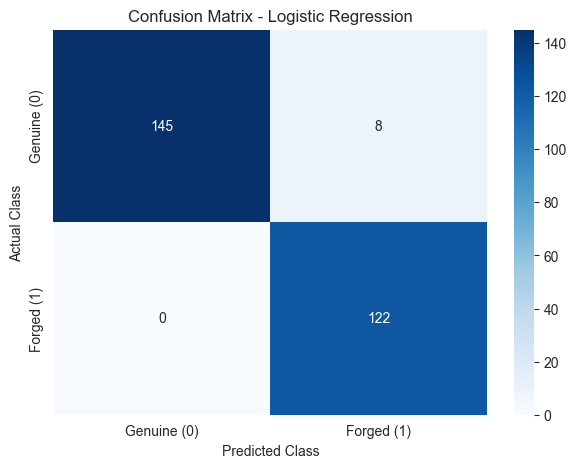

In [52]:
# Step 34: Confusion Matrix Visualization

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Genuine (0)', 'Forged (1)'],
    yticklabels=['Genuine (0)', 'Forged (1)']
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

In [53]:
# Step 35: Threshold Comparison

thresholds = [0.30, 0.50, 0.70]

threshold_results = []

for threshold in thresholds:

    # Generate predictions using the selected threshold
    threshold_pred = (
        y_prob[:, 1] >= threshold
    ).astype(int)

    # Calculate evaluation metrics
    acc = accuracy_score(y_test, threshold_pred)

    prec = precision_score(
        y_test,
        threshold_pred,
        zero_division=0
    )

    rec = recall_score(
        y_test,
        threshold_pred,
        zero_division=0
    )

    f1_value = f1_score(
        y_test,
        threshold_pred,
        zero_division=0
    )

    # Calculate confusion matrix
    cm_threshold = confusion_matrix(
        y_test,
        threshold_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm_threshold.ravel()

    # Store results
    threshold_results.append({
        'Threshold': threshold,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1 Score': f1_value,
        'TN': tn,
        'FP': fp,
        'FN': fn,
        'TP': tp
    })

# Display comparison table
threshold_df = pd.DataFrame(threshold_results)

print("THRESHOLD COMPARISON RESULTS")

display(threshold_df.round(4))


THRESHOLD COMPARISON RESULTS


,Threshold,Accuracy,Precision,Recall,F1 Score,TN,FP,FN,TP
0,0.3,0.9709,0.9385,1.0,0.9683,145,8,0,122
1,0.5,0.9709,0.9385,1.0,0.9683,145,8,0,122
2,0.7,0.9964,0.9919,1.0,0.9959,152,1,0,122


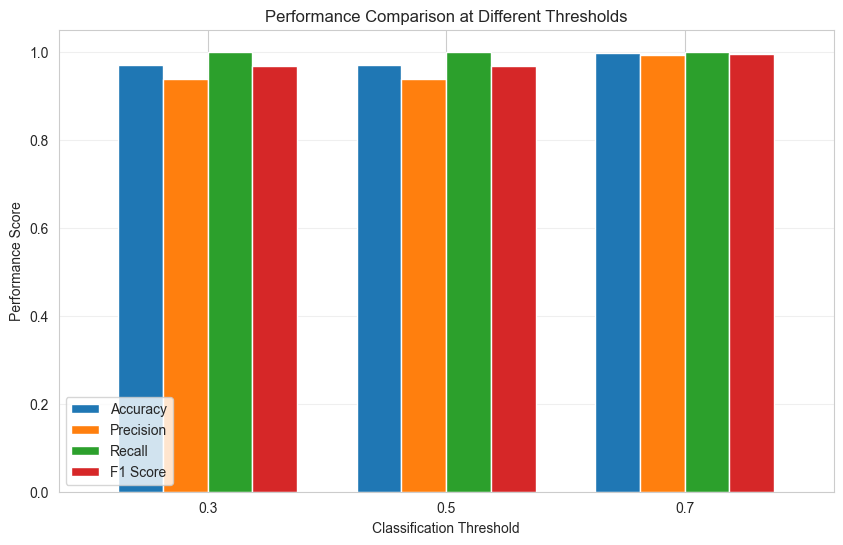

In [54]:
# Step 36: Threshold Performance Graph

metrics = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1 Score'
]

threshold_df.set_index('Threshold')[metrics].plot(
    kind='bar',
    figsize=(10, 6),
    width=0.75
)

plt.title("Performance Comparison at Different Thresholds")

plt.xlabel("Classification Threshold")

plt.ylabel("Performance Score")

plt.ylim(0, 1.05)

plt.xticks(rotation=0)

plt.legend(loc='lower left')

plt.grid(axis='y', alpha=0.3)

plt.show()

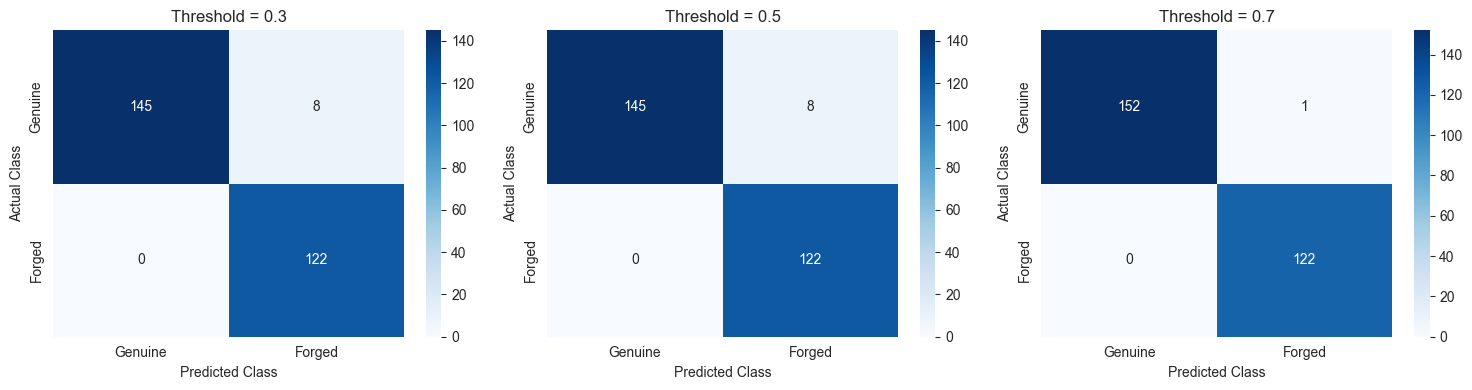

In [55]:
# Step 37: Confusion Matrices for Three Thresholds

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, threshold in zip(axes, thresholds):

    threshold_pred = (
        y_prob[:, 1] >= threshold
    ).astype(int)

    cm_threshold = confusion_matrix(
        y_test,
        threshold_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm_threshold,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax,
        xticklabels=['Genuine', 'Forged'],
        yticklabels=['Genuine', 'Forged']
    )

    ax.set_title(f'Threshold = {threshold}')
    ax.set_xlabel('Predicted Class')
    ax.set_ylabel('Actual Class')

plt.tight_layout()

plt.show()